# Project Group - 20

Members: 
1) Savino Every
2) Nicholas Johnson
3) Gijs van Vliet
4) Dániel Seesink
5) Delano van den Bosch


# Contribution Statement

*Be specific. Some of the tasks can be coding (expect everyone to do this), background research, conceptualisation, visualisation, data analysis, data modelling*

**Author 1**:

**Author 2**:

**Author 3**:

**Author 4**:

**Author 5**:

# Introduction

## 1.1 Context

context

## 1.2 Problem statement

problem statement

## 1.3 Research Objective & Question

*Requires data modeling and quantitative research in Transport, Infrastructure & Logistics*

Mention & justify the indicators

# Methodology

text

## 2.1 Imports

text


CANCELLATION-DAY FILTER
Percentile used: 90th
Cancellation threshold: 201.0 per day
Days excluded: 14 of 137
Trains removed: 12480
Trains remaining: 85236
DELAYS AND CANCELLATIONS
Number of complete cancellations: 7919
    25.0% of trains were delayed.
    9.8% of train operations were delayed by at least 3 minutes.
    9.3% of trains were cancelled.

RELATIVE PERFORMANCE
    Delay per vehicle: 1.22 minutes
    Delay per day: 845.5 minutes
    Cancellations per 100 vehicles: 9.29
    Cancellations per day: 64.38


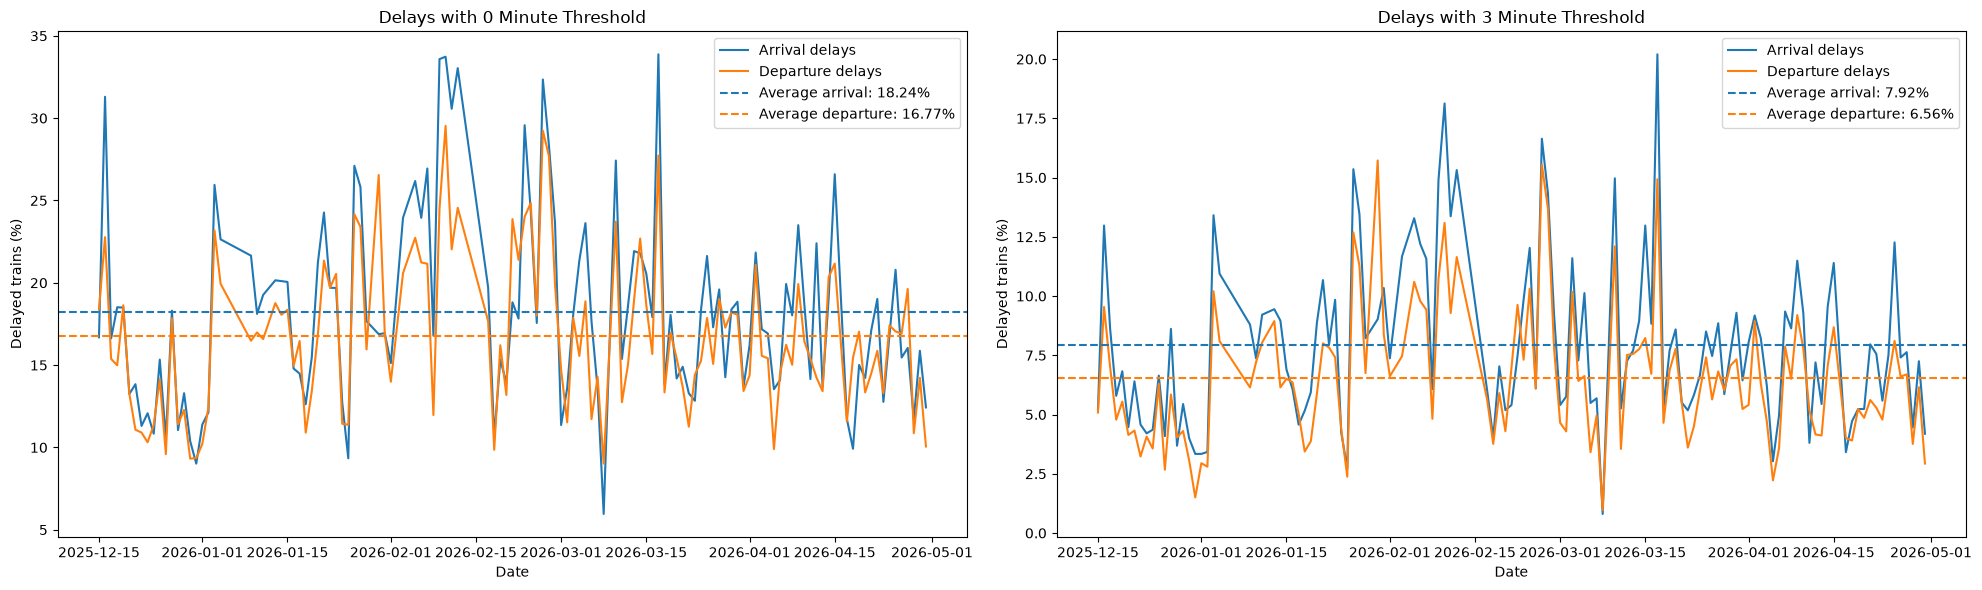

In [ ]:
from background.WIP_train_analysis import (
    load_train_data,
    filter_cancellation_days,
    analyse_delays,
    analyse_delay_spread,
    analyse_delays_per_hour,
    analyse_punctuality,
    analyse_delay_absorption,
    analyse_correlations
)

train = load_train_data()
train = filter_cancellation_days(
    train,
    cancellation_percentile=90
)

## 2.2 Data Used

Describe data cleaning and modification of both datasets (period_selection.ipynb 1. to 3., except initialisation of delay variables)

## 2.3 Data Pipeline

# Results

## 3.1 Weather analysis

## 3.2 Train analysis - Total period

The train data usage, cleaning and modification is described in section 2.2. For background, see /background/period_selection.ipynb and background/train_analysis.py.

The train analysis creates a baseline for the comparison analysis; an initial data pipeline is created to identify the generic indicators and insights which can be retreived from the data.

The three indicators and justification used are as follows:
- Delay indicator: 
    - Every arrival- and departure delay is flagged if the delay column > 0. 
    - An additional binary indicator is more important, however, which is the arrival and departure delay being bigger or equal to three (3) minutes or 180 seconds. This is the delay value indicated in NS' performance agreements as communicated to passengers and stakeholders [1].
- Number of cancellations:
    - A train is cancelled if either arrival or departure is cancelled.
    - Cancellations can be per hour, day, week of day or the average over the analysis period.
- Punctuality performance:
    - Punctuality of a train is the number of on-time events (on-time indicating delays being smaller than 180 seconds) divided by the total scheduled events.
    - Punctuality can differ at arrival, departure and a total punctuality figure.
    - Keeping non-cancalled trains in this dataset

### 3.2.1 Delays and cancellations in numbers

In [ ]:
delayed_trains = (len(train[(train['arrival_delayed'] == True) | (train['departure_delayed'] == True)])) / len(train) * 100
delayed_operations = len(train[(train['arrival_delayed_3'] == True) | (train['departure_delayed_3'] == True)]) / len(train) * 100
total_cancellations = len(train[train['cancelled'] == True])
total_cancellations_perct = total_cancellations / len(train) * 100

print(f"{delayed_trains:.1f}% of trains were delayed.")
print(f"{delayed_operations:.1f}% of train operations were delayed by more than 3 minutes (actual delay classification).")
print(f"{total_cancellations_perct:.1f}% of trains were completely cancelled.")

delay = analyse_delays(train)

25.0% of trains were delayed.
9.8% of train operations were delayed by more than 3 minutes (actual delay classification).
9.3% of trains were completely cancelled.


### 3.2.2 Delays per hour

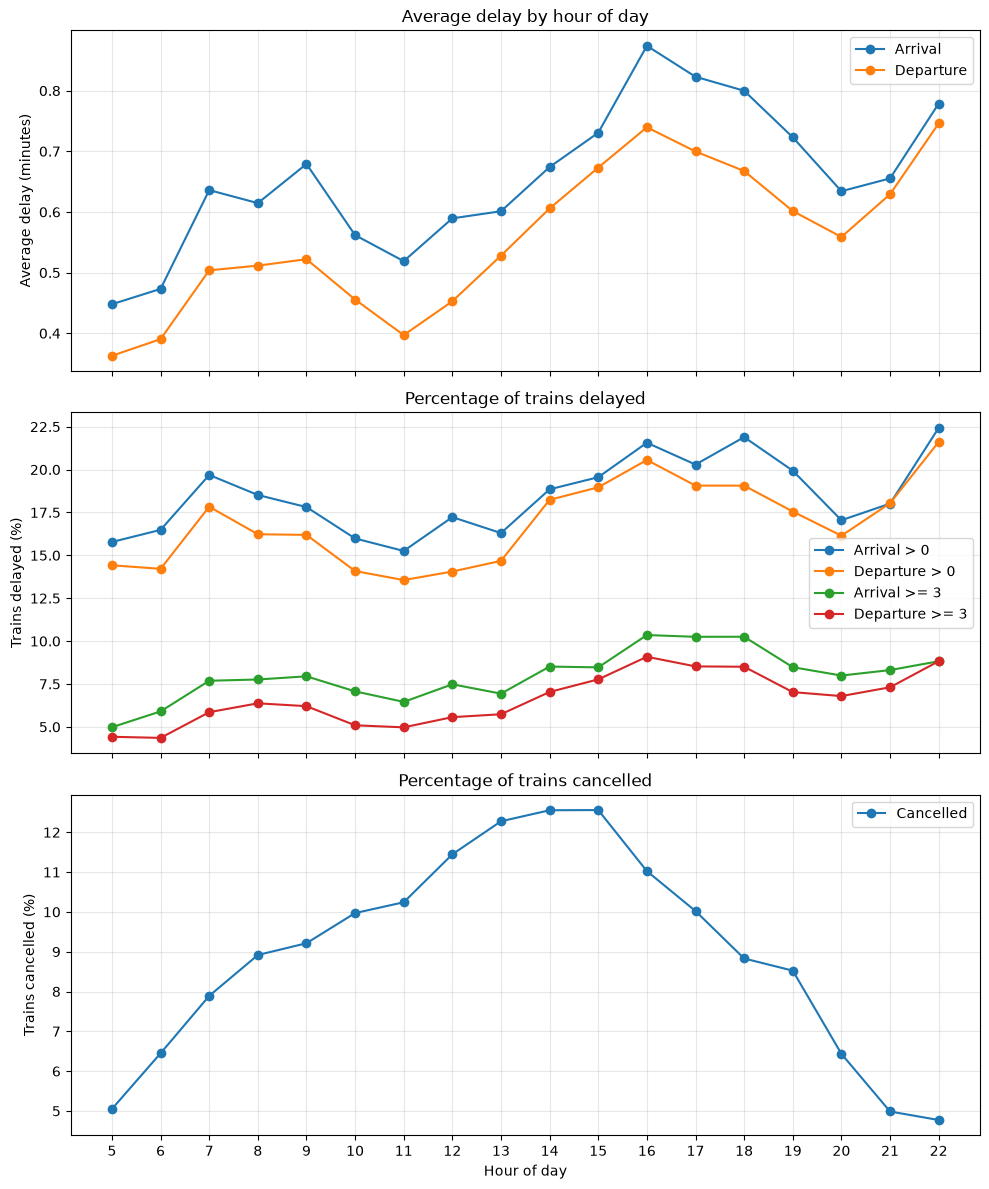

In [29]:
delay_per_hour = analyse_delays_per_hour(train)

### 3.2.3 Punctuality

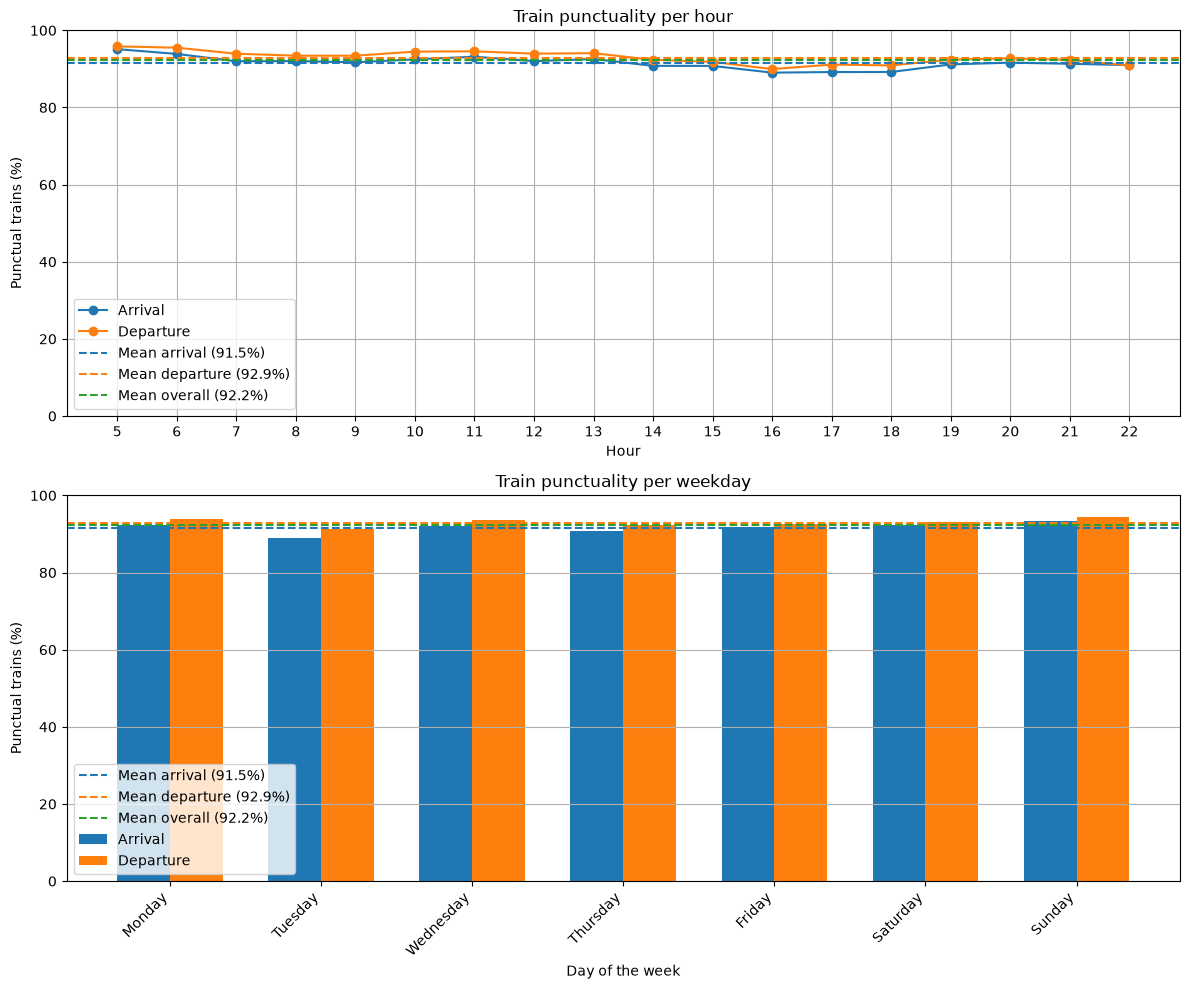

Trains punctual at both arrival and departure: 89.85%
Trains punctual at arrival: 91.53%
Trains punctual at departure: 92.94%


(            Date       Type   train_id scheduled_arrival  arr_delay  \
 1     2025-12-15  Intercity  157397373             05:07        0.0   
 2     2025-12-15  Intercity  157397715             05:06        2.0   
 3     2025-12-15  Intercity  157396972             05:09        1.0   
 4     2025-12-15   Sprinter  157397244             05:11        0.0   
 5     2025-12-15   Sprinter  157398903             05:11        0.0   
 ...          ...        ...        ...               ...        ...   
 97711 2026-04-30  Intercity  165792010             22:27        0.0   
 97712 2026-04-30   Sprinter  165792131             22:34        0.0   
 97713 2026-04-30  Intercity  165791852             22:37        0.0   
 97714 2026-04-30  Intercity  165792607             22:47        2.0   
 97715 2026-04-30  Intercity  165790497             22:52        3.0   
 
       arr_cancelled scheduled_departure  dep_delay dep_cancelled  \
 1             False               05:09        0.0         False

In [31]:
analyse_punctuality(train)

### 3.2.4 Delay absorption and propagation

The mean train delay change in total set equals: 0.1 minutes
The mean train delay change in selected set equals: 0.3 minutes
The maximum delay accumulated is -31.0 minutes and the maximum delay absorbed is 8.0 minutes
Overall delay absorption: 12.22%
Overall net delay change: -0.32 minutes per train
Late arrival delay absorption: 31.02%
Net delay change (departure delay minus arrival delay): -6399.0 minutes


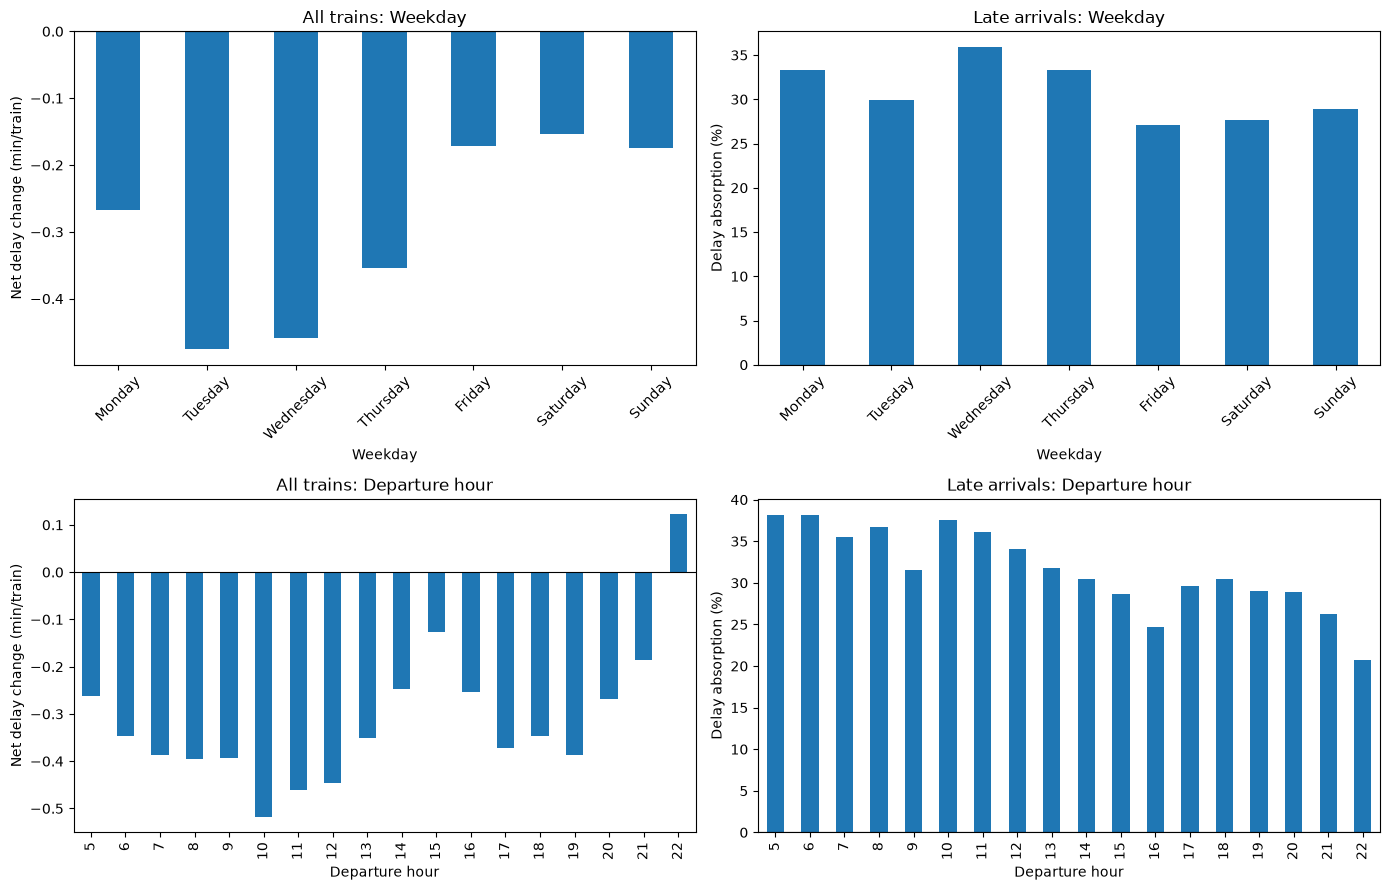

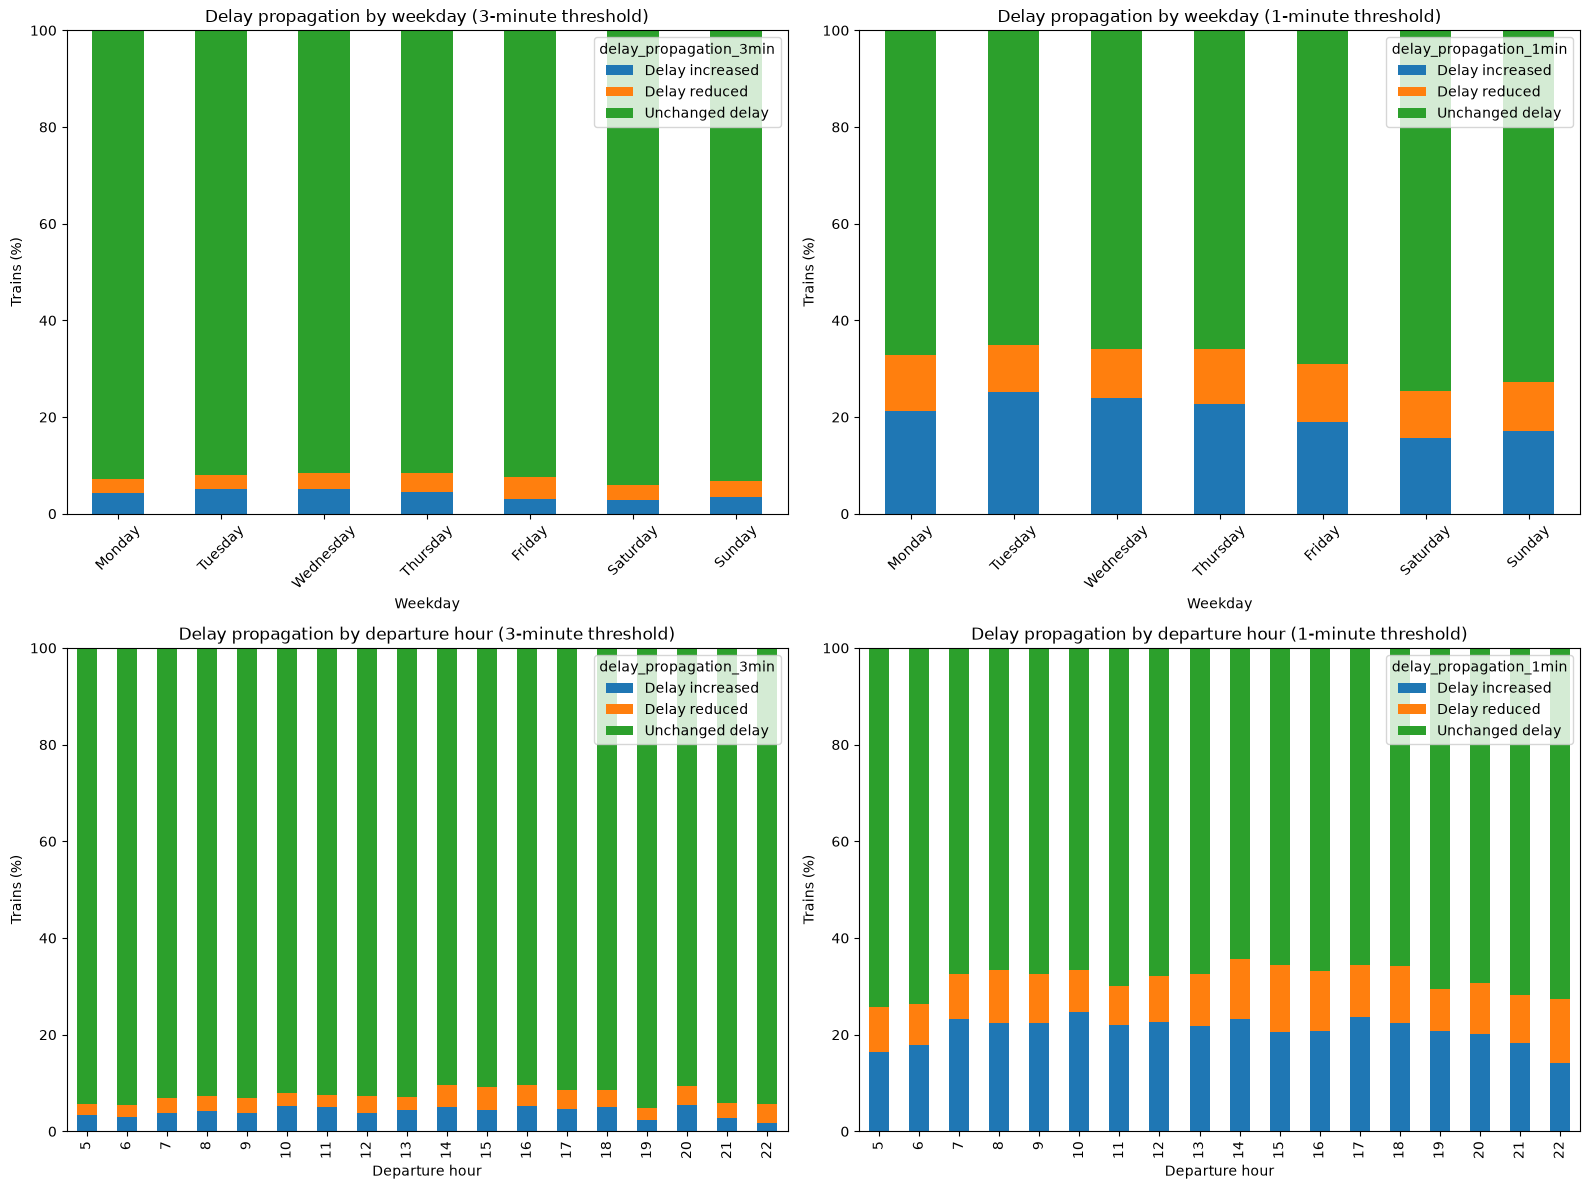

(            Date       Type   train_id scheduled_arrival  arr_delay  \
 2     2025-12-15  Intercity  157397715             05:06        2.0   
 3     2025-12-15  Intercity  157396972             05:09        1.0   
 6     2025-12-15   Sprinter  157396919             05:14        0.0   
 7     2025-12-15  Intercity  157397785             05:17        1.0   
 9     2025-12-15  Intercity  157396443             05:23        0.0   
 ...          ...        ...        ...               ...        ...   
 97694 2026-04-30  Intercity  165787910             21:51        1.0   
 97705 2026-04-30   Sprinter  165790889             22:14        0.0   
 97707 2026-04-30  Intercity  165791760             22:17        2.0   
 97714 2026-04-30  Intercity  165792607             22:47        2.0   
 97715 2026-04-30  Intercity  165790497             22:52        3.0   
 
       arr_cancelled scheduled_departure  dep_delay dep_cancelled  \
 2             False               05:09        0.0         False

In [32]:
analyse_delay_absorption(train)

### 3.2.3 Correlation and dwell-time heatmaps

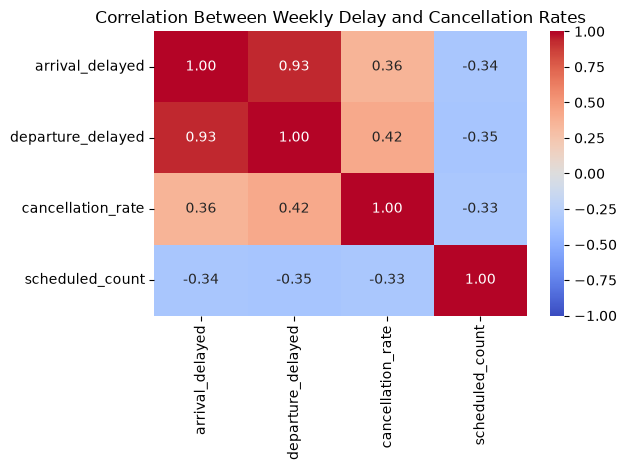

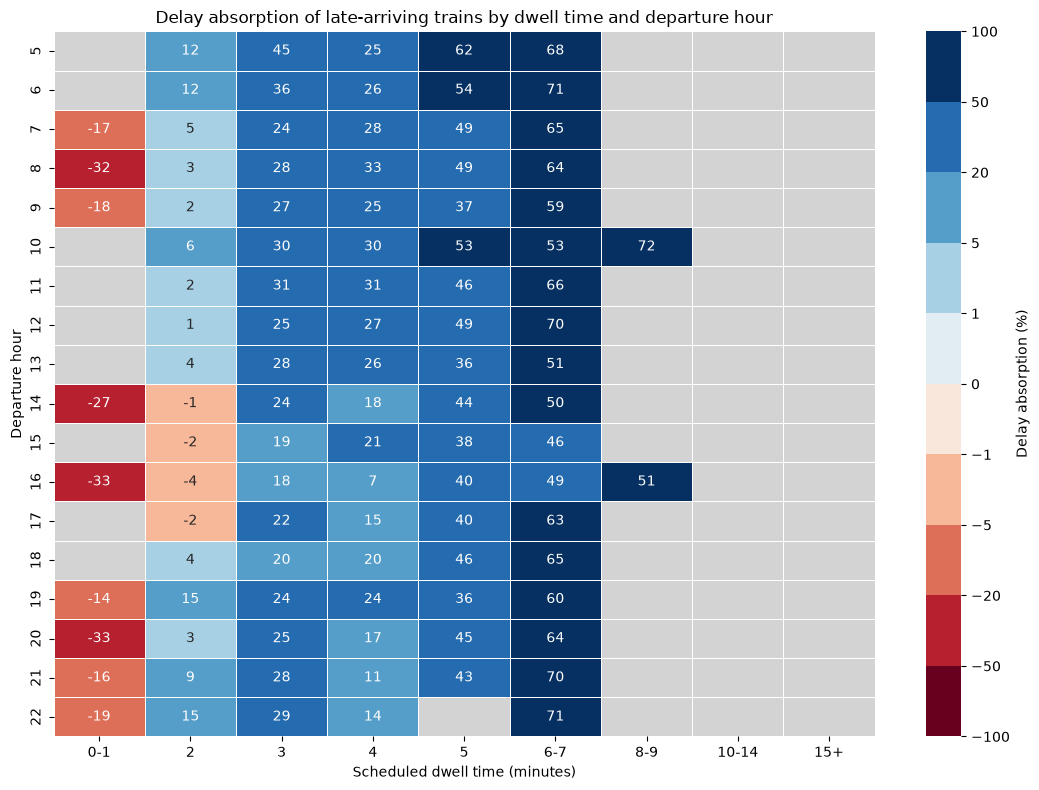

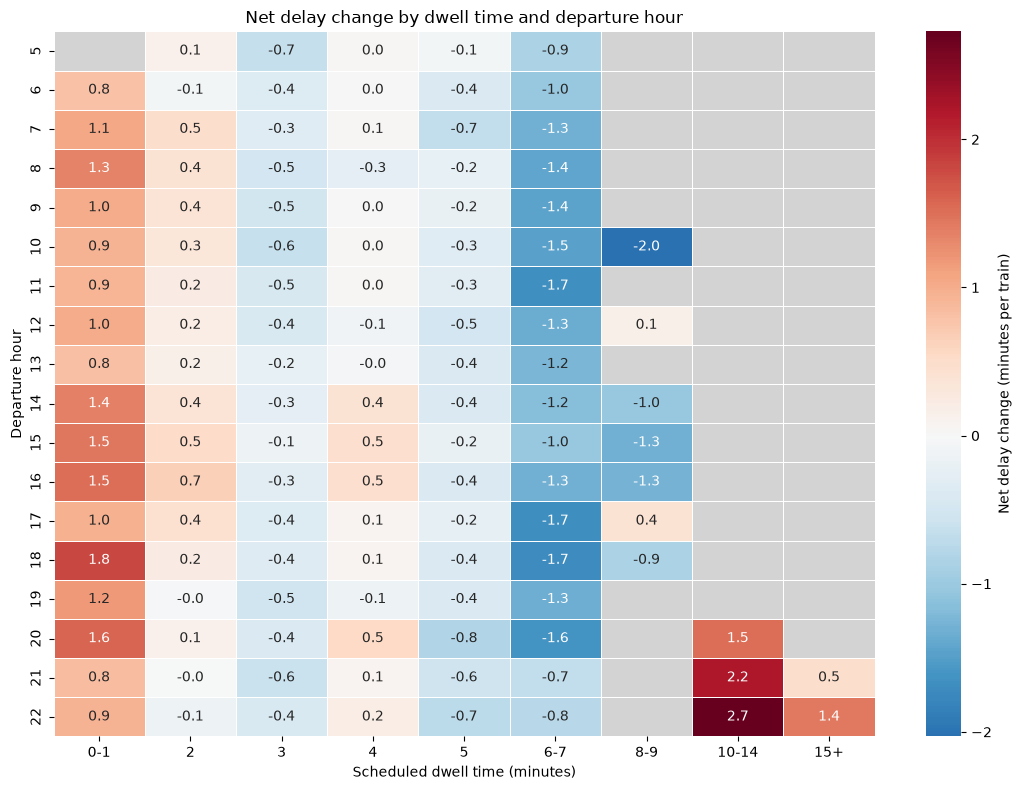

{'weekly_data':                        arrival_delayed  departure_delayed  cancellation_rate  \
 week                                                                           
 2025-12-15/2025-12-21         5.186804           4.193164           6.577901   
 2025-12-22/2025-12-28         3.504274           2.905983           7.371795   
 2025-12-29/2026-01-04         4.779333           3.379978          12.701830   
 2026-01-05/2026-01-11         6.608157           5.730511          24.212700   
 2026-01-12/2026-01-18         4.907099           4.192473          10.362077   
 2026-01-19/2026-01-25         5.378683           4.350405           7.929603   
 2026-01-26/2026-02-01         7.990599           7.990599          19.835488   
 2026-02-02/2026-02-08         8.306709           6.128376           9.642753   
 2026-02-09/2026-02-15        11.511015           8.470369          11.728204   
 2026-02-16/2026-02-22         4.088504           4.064454           4.689755   
 2026-02-23/2

In [30]:
analyse_correlations(train)

Recognize difference between delay and punctuality

In [27]:
# from background.train_analysis import train_analysis

# train, results = train_analysis(verbose=True)

## 3.3 Train analysis - Selected period

Same as above

## 3.4 Comparison analysis

# Conclusion

# Discussion

### AI Statement:

We, as a group, acknowledge the use of ChatGPT and Claude in preparing this submission. We used it for the following purposes:
- Brainstorming ahead of team meetings
- Concatenating data flows after creation (e.g. having AI assist to create a code which was in a .ipynb to convert to a .py after validation to use as an import definition)
- Providing feedback/advice on how to improve the basic matplotlib plots (...)
- ...

We confirm that we have critically reviewed and verfied all AI-assisted content per part used and that the submitted work reflects our own understanding according to the task division. We take full responsibility for the accuracy and orginality of the combination of AI usage and project applicance.

# Sources

[1] https://nsannualreport.nl/annual-report-2025/performance-what-we-have-achieved/our-operations/performance-agreements